In [2]:
# libraries
import os

os.environ["PROJ_LIB"] = "${HOME}/miniconda3/share/proj"
from mpl_toolkits.basemap import Basemap
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from config import Continent
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon
from mpl_toolkits.basemap import Basemap

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
COUNTRY_COORDS_FILE = "./data/world_country_lon_lat.csv"
# COUNTRY_COORDS_FILE = "./data/eu_country_lon_lat_extended.csv"
COUNTRY_MOVIE_FILE = "./data/unesco_movie_producing.csv"
SHAPE_FILE = "./data/natural_earth/ne_10m_admin_0_countries"  ## w/o extension

REGION = 'world'
INDICATOR = 'Total number of national feature films produced'
INDICATOR = 'Indoor cinemas per capita (per 1,000,000 inhabitants)'
YEAR = 2011
TITLE = "{} in {}".format(INDICATOR, YEAR)
TEXT_OFFSET = 0
LOWER_LATITUDE_OFFSET = 1
N_COLORS = 10
MOVIE_COUNT_TEXT_FONTSIZE = 10
RESOLUTION = 'c'  ## c, l, i, h, f
FIGURE_SIZE = (10, 5)

In [6]:
## Set region and its coordinates
if REGION == 'europe':
    region = Continent.europe
elif REGION == 'world':
    region = Continent.world
else:
    print("{} is not available. Choose from ['world', 'europe']".format(REGION))
    exit()

region_llcrnrlon = region['llcrnrlon']
region_llcrnrlat = region['llcrnrlat']
region_urcrnrlon = region['urcrnrlon']
region_urcrnrlat = region['urcrnrlat']
region_lat0 = region['lat_0']
region_lon0 = region['lon_0']
region_lat1 = region['lat_1']
region_lat2 = region['lat_2']

## Read country coordinates
df_region = pd.read_csv(COUNTRY_COORDS_FILE)

## Read gnp values
df_movie = pd.read_csv(COUNTRY_MOVIE_FILE)

## Merge with region df
merged = pd.merge(df_movie, df_region, left_on='Country', right_on='name')[['Indicator', 'Country', 'Time', 'Value', 'lon', 'lat']]
df = merged.dropna()
df = df[df['Indicator'] == INDICATOR]
df = df[df['Time'] == YEAR]

In [8]:
df.head()
# df[df['Country'] == "People's Republic of China"]

,Indicator,Country,Time,Value,lon,lat
4419,"Indoor cinemas per capita (per 1,000,000 inhab...",Australia,2011,23.5,133.775136,-25.274398
4431,"Indoor cinemas per capita (per 1,000,000 inhab...",Austria,2011,20.6,14.550072,47.516231
4442,"Indoor cinemas per capita (per 1,000,000 inhab...",Belgium,2011,11.0,4.469936,50.503887
4456,"Indoor cinemas per capita (per 1,000,000 inhab...",Denmark,2011,32.1,9.501785,56.263920
4469,"Indoor cinemas per capita (per 1,000,000 inhab...",Finland,2011,34.4,25.748151,61.924110


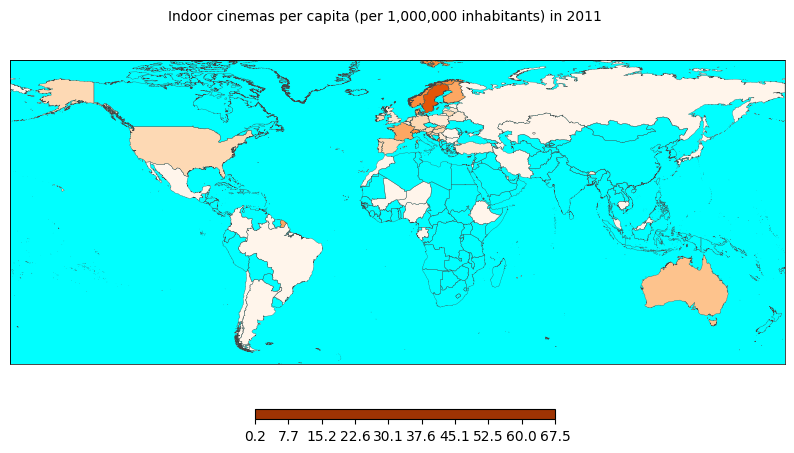

In [14]:
## Set digitized color intervals
movie_counts = df['Value']
cm = plt.get_cmap('Oranges')
scheme = np.array([cm(i / N_COLORS) for i in range(N_COLORS)])
bins = np.linspace(movie_counts.min(), movie_counts.max(), N_COLORS)
df['bin'] = np.digitize(movie_counts, bins) - 1

## Figure
fig = plt.figure(figsize=FIGURE_SIZE)
ax = fig.add_subplot(111, frame_on=False)
fig.suptitle(TITLE, fontsize=10, y=.90)

# Control the position of the square. Give the coordinate of 2 corners
if REGION == 'world':
    m = Basemap(
                llcrnrlon=region_llcrnrlon,
                llcrnrlat=region_llcrnrlat - LOWER_LATITUDE_OFFSET,
                urcrnrlon=region_urcrnrlon,
                urcrnrlat=region_urcrnrlat,
                projection='cyl',
                resolution=RESOLUTION,
                area_thresh=1,
            )
else:
    m = Basemap(
                llcrnrlon=region_llcrnrlon,
                llcrnrlat=region_llcrnrlat - LOWER_LATITUDE_OFFSET,
                urcrnrlon=region_urcrnrlon,
                urcrnrlat=region_urcrnrlat,
                lat_0=region_lat0,
                lon_0=region_lon0,
                lat_1=region_lat1,
                lat_2=region_lat2,
                projection='lcc',
                resolution=RESOLUTION,
                area_thresh=1,
            )
# Draw the components of the map
m.drawmapboundary(fill_color='aqua', linewidth=0.5)
# m.drawcountries(color='white', linewidth=0.5)
# m.drawlsmask(land_color='white',
#              ocean_color='aqua',
#              lakes=False,
#              resolution='f',
#              grid=1.25)

## Write GNP value text 
if REGION != 'world':
    for country in np.array(df):
        indicator, country, time, n_movie, lon, lat, _ = country
        x, y = m(lon, lat)   ## Map projection
        x_off, y_off = x + TEXT_OFFSET, y + TEXT_OFFSET
        lon, lat = m(x, y, inverse=True)  ## Back to longitude-latitude
        n_movie_str = str(n_movie)
        plt.text(x_off, y_off, '{}'.format(n_movie_str), fontsize=MOVIE_COUNT_TEXT_FONTSIZE)

## Color the countries
m.readshapefile(SHAPE_FILE, 'units', color='#444444', linewidth=.2)
country_names_in_df = np.array(df['Country'])
for info, shape in zip(m.units_info, m.units):
    ne_name = info['NAME_EN'].strip()
    # if "orea" in ne_name:  ## 
    #     print(ne_name)
    if ne_name not in country_names_in_df: 
        continue

    color = scheme[df[df['Country'] == ne_name]['bin']]
    patches = [Polygon(np.array(shape))]
    pc = PatchCollection(patches)
    pc.set_facecolor(color)
    ax.add_collection(pc)

## Draw color legend
ax_legend = fig.add_axes([0.37, 0.08, 0.3, 0.02], zorder=3)
cmap = mpl.colors.ListedColormap(scheme)
cb = mpl.colorbar.ColorbarBase(ax_legend,
                               cmap=cmap,
                               ticks=bins,
                               boundaries=bins,
                               orientation='horizontal')
cb.ax.set_xticklabels([str(round(i, 1)) for i in bins])

plt.show()